In [ ]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# 1. Läs in data och ta bort målvariabeln 'target'
df = pd.read_csv('data_grupp_13.csv')
X = df.drop(columns=['target'])

# 2. Skala datan
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 3. Kör K-means med enbart standardinställningar och random_state=42
kmeans = KMeans(random_state=42)
kmeans_labels = kmeans.fit_predict(X_scaled)

# 4. Skriv ut resultatet
print("=== K-means (standardinställningar) ===")
print(f"Antal kluster (default): {kmeans.n_clusters}")
print("\nAntal observationer per kluster:")
print(pd.Series(kmeans_labels).value_counts().sort_index())

=== Systematisk undersökning av K-means (k = 2..8) ===
 n_clusters (k)  Inertia (WCSS)  Silhouette Score
              2          882.99            0.3825
              3          443.92            0.5032
              4          407.72            0.4031
              5          368.64            0.3169
              6          338.66            0.2876
              7          309.01            0.1883
              8          297.92            0.1821


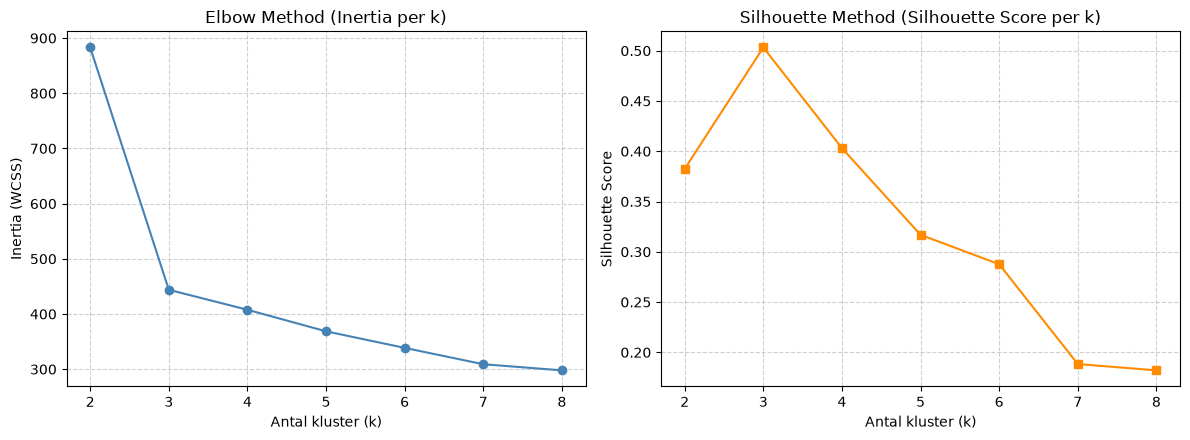


=== Optimerad K-means (n_clusters=3, random_state=42) ===
Inertia (WCSS): 443.92
Silhouette Score: 0.5032

Antal observationer per kluster:
0    80
1    80
2    80
Name: count, dtype: int64


In [7]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# 1. Läs in data och ta bort målvariabeln 'target'
df = pd.read_csv('data_grupp_13.csv')
X = df.drop(columns=['target'])

# 2. Skala datan
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 3. Systematisk undersökning av k = 2 till och med 8 (Elbow & Silhouette)
k_values = range(2, 9)
inertias = []
sil_scores = []

for k in k_values:
    km = KMeans(n_clusters=k, random_state=42)
    labels = km.fit_predict(X_scaled)
    inertias.append(km.inertia_)
    sil_scores.append(silhouette_score(X_scaled, labels))

# Skriv ut resultat i en tabell
results_df = pd.DataFrame({
    'n_clusters (k)': list(k_values),
    'Inertia (WCSS)': [round(val, 2) for val in inertias],
    'Silhouette Score': [round(val, 4) for val in sil_scores]
})
print("=== Systematisk undersökning av K-means (k = 2..8) ===")
print(results_df.to_string(index=False))

# 4. Visualisera Elbow Method och Silhouette Score
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

ax1.plot(k_values, inertias, marker='o', color='steelblue')
ax1.set_title('Elbow Method (Inertia per k)')
ax1.set_xlabel('Antal kluster (k)')
ax1.set_ylabel('Inertia (WCSS)')
ax1.set_xticks(list(k_values))
ax1.grid(True, linestyle='--', alpha=0.6)

ax2.plot(k_values, sil_scores, marker='s', color='darkorange')
ax2.set_title('Silhouette Method (Silhouette Score per k)')
ax2.set_xlabel('Antal kluster (k)')
ax2.set_ylabel('Silhouette Score')
ax2.set_xticks(list(k_values))
ax2.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

# 5. Kör optimerad K-means med det bästa k-värdet
best_k = list(k_values)[sil_scores.index(max(sil_scores))]
kmeans_opt = KMeans(n_clusters=best_k, random_state=42)
opt_labels = kmeans_opt.fit_predict(X_scaled)

print(f"\n=== Optimerad K-means (n_clusters={best_k}, random_state=42) ===")
print(f"Inertia (WCSS): {kmeans_opt.inertia_:.2f}")
print(f"Silhouette Score: {silhouette_score(X_scaled, opt_labels):.4f}")
print("\nAntal observationer per kluster:")
print(pd.Series(opt_labels).value_counts().sort_index())

=== PCA (>= 90 % förklarad varians) ===
Antal valda huvudkomponenter: 4
Förklarad varians per komponent: [0.4847 0.3053 0.0875 0.0616]
Total förklarad varians: 93.92 %

=== Systematisk undersökning av K-means efter PCA (>= 90%) ===
 n_clusters (k)  Inertia (PCA >= 90%)  Silhouette (PCA >= 90%)
              2                795.77                   0.4150
              3                357.38                   0.5534
              4                318.63                   0.4653
              5                292.18                   0.4261
              6                257.35                   0.3278
              7                244.35                   0.3098
              8                213.35                   0.2178


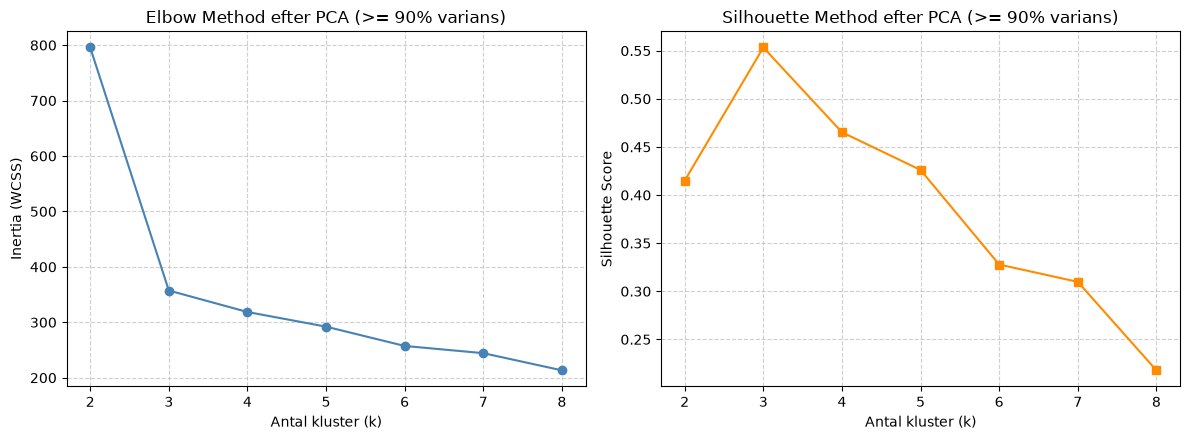


=== Optimerad K-means efter PCA >= 90% (n_clusters=3) ===
Inertia (WCSS): 357.38
Silhouette Score: 0.5534
Exekveringstid: 6.4742 ms

Antal observationer per kluster:
0    80
1    80
2    80
Name: count, dtype: int64


In [8]:
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# 1. Läs in data och ta bort målvariabeln 'target'
df = pd.read_csv('data_grupp_13.csv')
X = df.drop(columns=['target'])

# 2. Skala datan
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 3. PCA med minst 90 % förklarad varians (n_components=0.90)
pca_90 = PCA(n_components=0.90, random_state=42)
X_pca_90 = pca_90.fit_transform(X_scaled)

print("=== PCA (>= 90 % förklarad varians) ===")
print(f"Antal valda huvudkomponenter: {pca_90.n_components_}")
print(f"Förklarad varians per komponent: {np.round(pca_90.explained_variance_ratio_, 4)}")
print(f"Total förklarad varians: {sum(pca_90.explained_variance_ratio_)*100:.2f} %")

# 4. Systematisk undersökning av k = 2 till och med 8 på PCA-reducerad data
k_values = range(2, 9)
inertias_pca = []
sil_scores_pca = []

for k in k_values:
    km = KMeans(n_clusters=k, random_state=42)
    labels = km.fit_predict(X_pca_90)
    inertias_pca.append(km.inertia_)
    sil_scores_pca.append(silhouette_score(X_pca_90, labels))

results_pca_df = pd.DataFrame({
    'n_clusters (k)': list(k_values),
    'Inertia (PCA >= 90%)': [round(val, 2) for val in inertias_pca],
    'Silhouette (PCA >= 90%)': [round(val, 4) for val in sil_scores_pca]
})
print("\n=== Systematisk undersökning av K-means efter PCA (>= 90%) ===")
print(results_pca_df.to_string(index=False))

# 5. Visualisera Elbow & Silhouette efter PCA (>= 90%)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

ax1.plot(k_values, inertias_pca, marker='o', color='steelblue')
ax1.set_title('Elbow Method efter PCA (>= 90% varians)')
ax1.set_xlabel('Antal kluster (k)')
ax1.set_ylabel('Inertia (WCSS)')
ax1.set_xticks(list(k_values))
ax1.grid(True, linestyle='--', alpha=0.6)

ax2.plot(k_values, sil_scores_pca, marker='s', color='darkorange')
ax2.set_title('Silhouette Method efter PCA (>= 90% varians)')
ax2.set_xlabel('Antal kluster (k)')
ax2.set_ylabel('Silhouette Score')
ax2.set_xticks(list(k_values))
ax2.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

# 6. Kör optimerad K-means på PCA-data med bästa k och mät exekveringstid
best_k_pca = list(k_values)[sil_scores_pca.index(max(sil_scores_pca))]

t0 = time.perf_counter()
kmeans_pca_opt = KMeans(n_clusters=best_k_pca, random_state=42)
opt_labels_pca = kmeans_pca_opt.fit_predict(X_pca_90)
t1 = time.perf_counter()

print(f"\n=== Optimerad K-means efter PCA >= 90% (n_clusters={best_k_pca}) ===")
print(f"Inertia (WCSS): {kmeans_pca_opt.inertia_:.2f}")
print(f"Silhouette Score: {silhouette_score(X_pca_90, opt_labels_pca):.4f}")
print(f"Exekveringstid: {(t1 - t0)*1000:.4f} ms")
print("\nAntal observationer per kluster:")
print(pd.Series(opt_labels_pca).value_counts().sort_index())